# **Iris Flower Classification Using Decision Tree and Random Forest Algorithms**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Load Iris dataset
data = load_iris(as_frame=True)

X = data.data
y = data.target

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Feature names:", list(X.columns))
print("Target classes:", list(data.target_names))

display(data.frame.head())

Dataset loaded successfully!
Dataset shape: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
# Check missing values
print("Missing values:")
print(X.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", data.frame.duplicated().sum())

# Check dataset information
print("\nDataset information:")
X.info()

# Check class distribution
print("\nClass distribution:")
print(y.value_counts().sort_index())

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
dtype: int64

Duplicate rows: 1

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB

Class distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


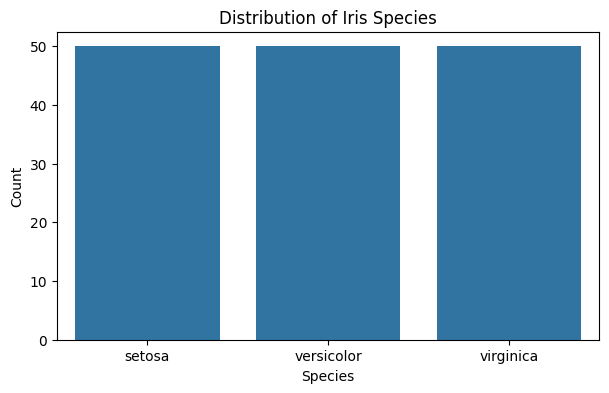

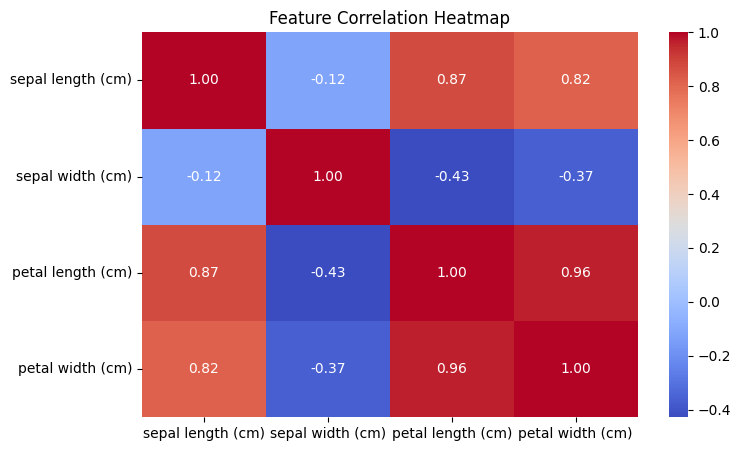

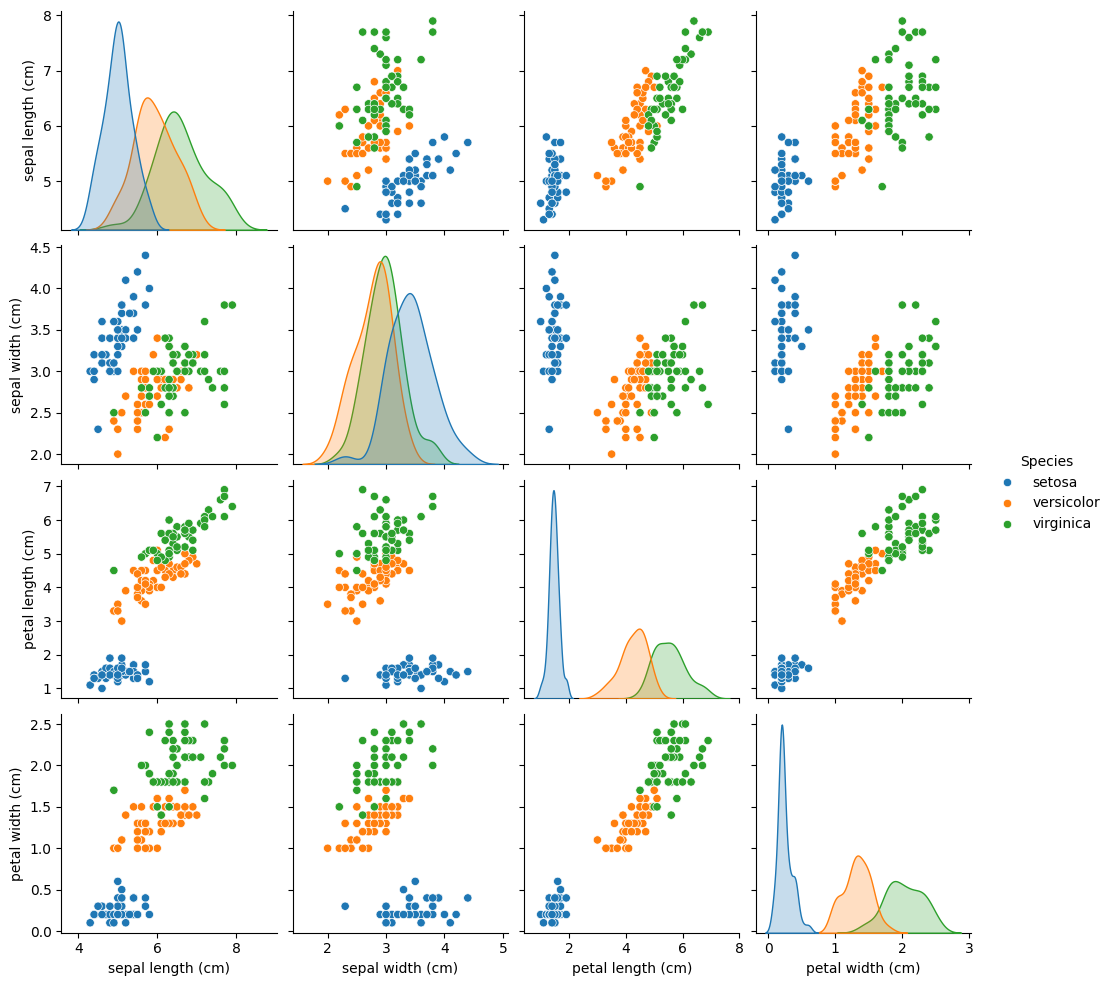

In [ ]:
# Summary statistics
display(X.describe())

# Plot class distribution
plt.figure(figsize=(7, 4))
sns.countplot(x=pd.Series(y).map(dict(enumerate(data.target_names))))
plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

# Pairplot
eda_data = X.copy()
eda_data["Species"] = pd.Series(y).map(dict(enumerate(data.target_names)))
sns.pairplot(eda_data, hue="Species")
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [ ]:
dt_model = DecisionTreeClassifier(
    max_depth=2,
    min_samples_leaf=4,
    random_state=42
)

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("Decision Tree Accuracy:",
      round(accuracy_score(y_test, dt_pred) * 100, 2), "%")

Decision Tree Accuracy: 93.33 %


In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42
)

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest Accuracy:",
      round(accuracy_score(y_test, rf_pred) * 100, 2), "%")

Random Forest Accuracy: 90.0 %


In [ ]:
results = pd.DataFrame({
    "Algorithm": ["Decision Tree", "Random Forest"],
    "Accuracy (%)": [
        accuracy_score(y_test, dt_pred) * 100,
        accuracy_score(y_test, rf_pred) * 100
    ]
})

results["Accuracy (%)"] = results["Accuracy (%)"].round(2)

display(results)

,Algorithm,Accuracy (%)
0,Decision Tree,93.33
1,Random Forest,90.00


In [ ]:
print("DECISION TREE CLASSIFICATION REPORT")
print(classification_report(
    y_test, dt_pred, target_names=data.target_names
))

print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test, rf_pred, target_names=data.target_names
))

DECISION TREE CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



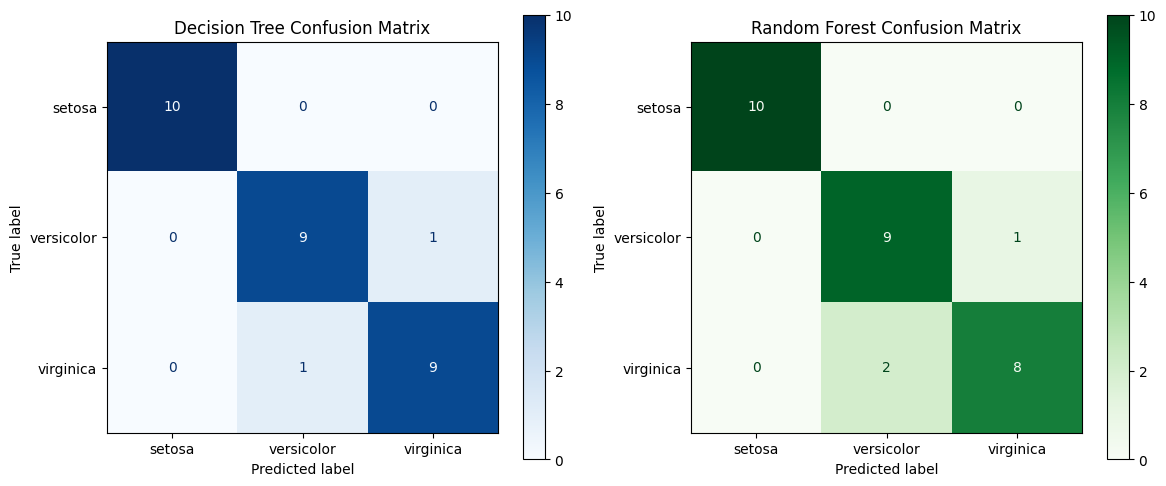

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    dt_pred,
    display_labels=data.target_names,
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Decision Tree Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    display_labels=data.target_names,
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("Random Forest Confusion Matrix")

plt.tight_layout()
plt.show()

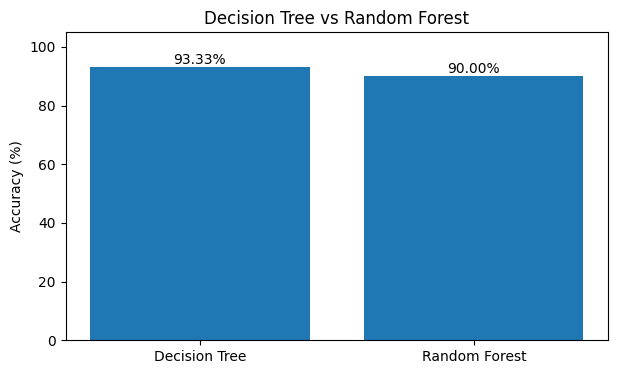

In [ ]:
plt.figure(figsize=(7, 4))

plt.bar(
    results["Algorithm"],
    results["Accuracy (%)"]
)

plt.title("Decision Tree vs Random Forest")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)

for i, value in enumerate(results["Accuracy (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

,Feature,Decision Tree,Random Forest
0,sepal length (cm),0.0000,0.1159
1,sepal width (cm),0.0000,0.0179
2,petal length (cm),0.5519,0.4538
3,petal width (cm),0.4481,0.4124


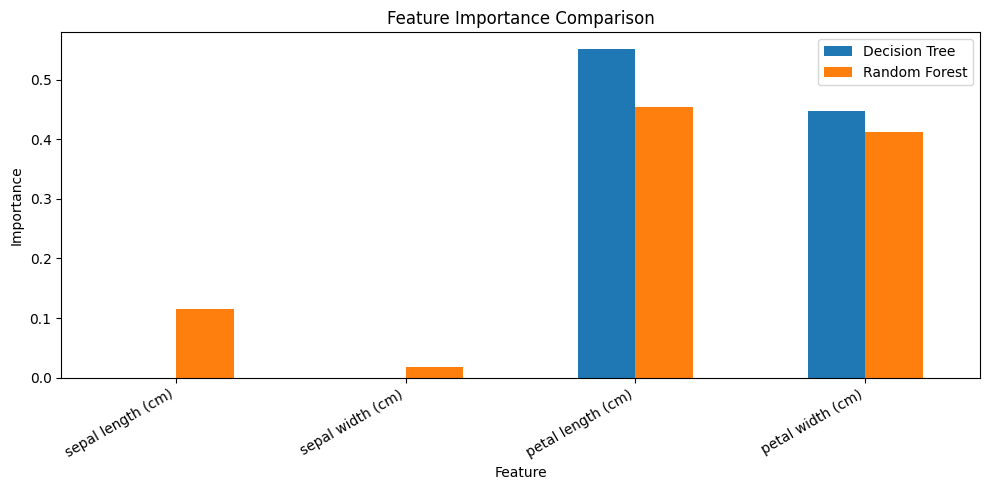

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Decision Tree": dt_model.feature_importances_,
    "Random Forest": rf_model.feature_importances_
})

display(importance.round(4))

importance.set_index("Feature").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Feature Importance Comparison")
plt.ylabel("Importance")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
sample = X_test.iloc[[0]]

dt_result = data.target_names[dt_model.predict(sample)[0]]
rf_result = data.target_names[rf_model.predict(sample)[0]]
actual_result = data.target_names[y_test.iloc[0]]

print("Sample input:")
display(sample)

print("Actual species:", actual_result)
print("Decision Tree prediction:", dt_result)
print("Random Forest prediction:", rf_result)

Sample input:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
38,4.4,3.0,1.3,0.2


Actual species: setosa
Decision Tree prediction: setosa
Random Forest prediction: setosa


In [ ]:
joblib.dump(dt_model, "decision_tree_classifier.pkl")
joblib.dump(rf_model, "random_forest_classifier.pkl")

metadata = {
    "features": list(X.columns),
    "target_names": list(data.target_names),
    "defaults": X.iloc[0].to_dict()
}

joblib.dump(metadata, "iris_metadata.pkl")

print("All models and metadata saved successfully!")

All models and metadata saved successfully!


In [ ]:
from google.colab import files

files.download("decision_tree_classifier.pkl")
files.download("random_forest_classifier.pkl")
files.download("iris_metadata.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>